In [1]:
import sys
print(sys.executable)

c:\Users\이채영\code_it_image_generation\.venv\Scripts\python.exe


# FashionMNIST EDA

cGAN으로 패션 아이템을 생성하기 전에, 데이터가 어떻게 생겼는지 먼저 확인해본다.

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from torchvision import datasets

# 실행할 때마다 같은 결과가 나오게 시드 고정
torch.manual_seed(42)
np.random.seed(42)

Matplotlib is building the font cache; this may take a moment.


In [4]:
# 변환 없이 원본 그대로 불러옴 (처음엔 다운로드됨)
train_set = datasets.FashionMNIST(root="../data", train=True, download=True)
test_set = datasets.FashionMNIST(root="../data", train=False, download=True)

class_names = train_set.classes
print("train:", len(train_set), "/ test:", len(test_set))
print("클래스:", class_names)

100%|██████████| 26.4M/26.4M [00:48<00:00, 549kB/s] 
100%|██████████| 29.5k/29.5k [00:00<00:00, 110kB/s]
100%|██████████| 4.42M/4.42M [00:06<00:00, 645kB/s] 
100%|██████████| 5.15k/5.15k [00:00<00:00, 5.18MB/s]


train: 60000 / test: 10000
클래스: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


In [5]:
X_train = train_set.data
y_train = train_set.targets

print("이미지 shape:", tuple(X_train.shape))
print("dtype:", X_train.dtype)
print("픽셀 최소/최대:", X_train.min().item(), "/", X_train.max().item())
print("픽셀 평균:", round(X_train.float().mean().item() / 255, 4))
print("픽셀 표준편차:", round(X_train.float().std().item() / 255, 4))

이미지 shape: (60000, 28, 28)
dtype: torch.uint8
픽셀 최소/최대: 0 / 255
픽셀 평균: 0.286
픽셀 표준편차: 0.353


In [ ]:
train_counts = torch.bincount(train_set.targets, minlength=10)
test_counts = torch.bincount(test_set.targets, minlength=10)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, counts, title in zip(axes, [train_counts, test_counts], ["train", "test"]):
    ax.bar(class_names, counts.numpy(), color="steelblue")
    ax.set_title(f"class count ({title})")
    ax.tick_params(axis="x", rotation=60)
plt.tight_layout()
plt.show()

print("train:", train_counts.tolist())
print("test:", test_counts.tolist())

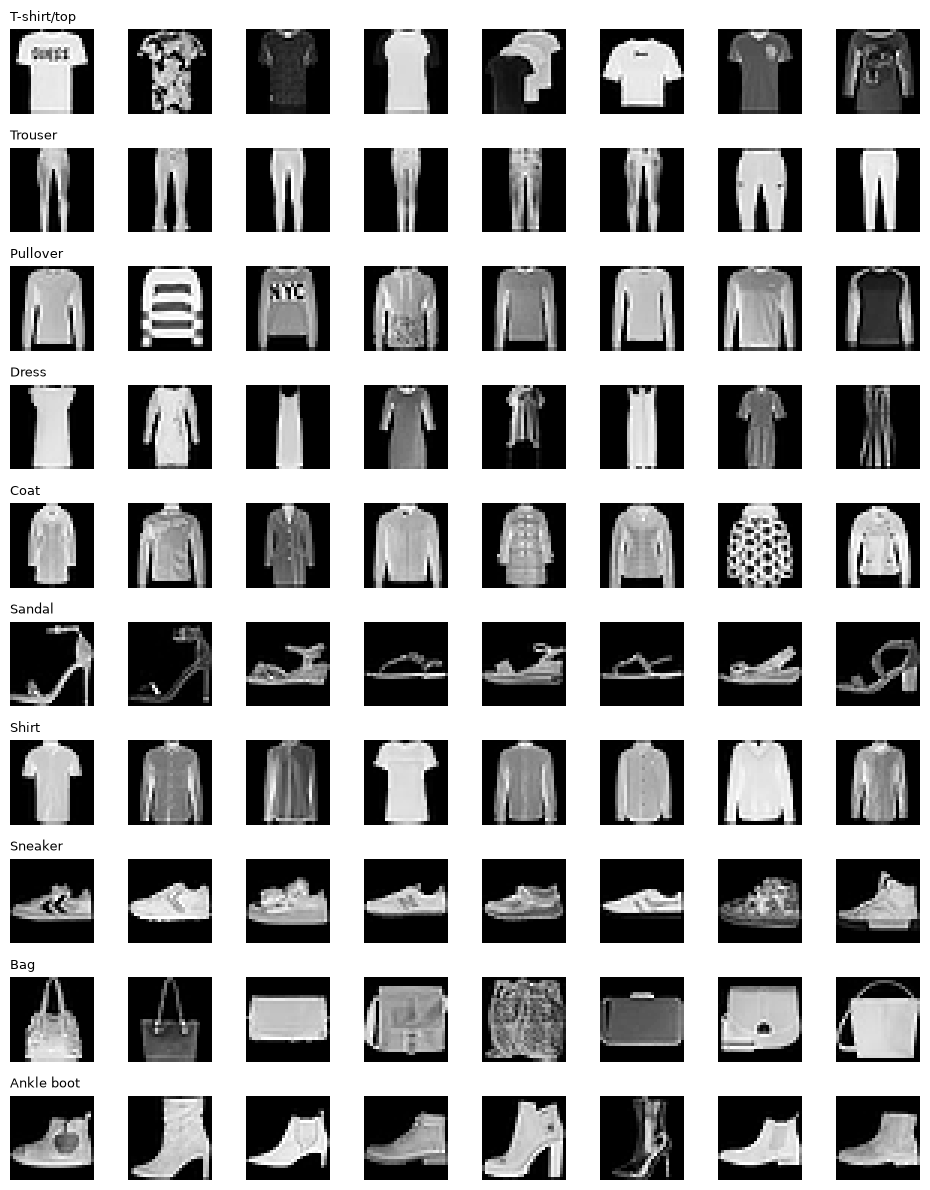

In [6]:
# 클래스마다 8장씩 랜덤으로 뽑아서 확인
n_per_class = 8
fig, axes = plt.subplots(10, n_per_class, figsize=(n_per_class * 1.2, 10 * 1.2))

for c in range(10):
    idxs = (y_train == c).nonzero(as_tuple=True)[0]
    picked = idxs[torch.randperm(len(idxs))[:n_per_class]]
    for j, idx in enumerate(picked):
        ax = axes[c, j]
        ax.imshow(X_train[idx], cmap="gray")
        ax.axis("off")
        if j == 0:
            ax.set_title(class_names[c], fontsize=9, loc="left")

plt.tight_layout()
plt.show()

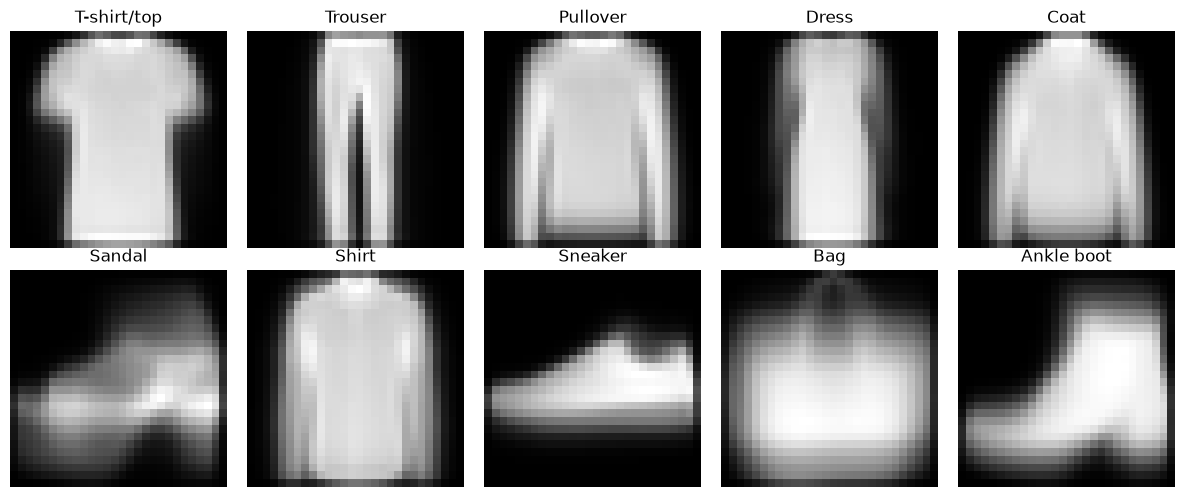

In [7]:
# 클래스별로 평균 내면 그 클래스의 대표 모양이 보임
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for c, ax in enumerate(axes.flat):
    mean_img = X_train[y_train == c].float().mean(dim=0)
    ax.imshow(mean_img, cmap="gray")
    ax.set_title(class_names[c])
    ax.axis("off")

plt.tight_layout()
plt.show()

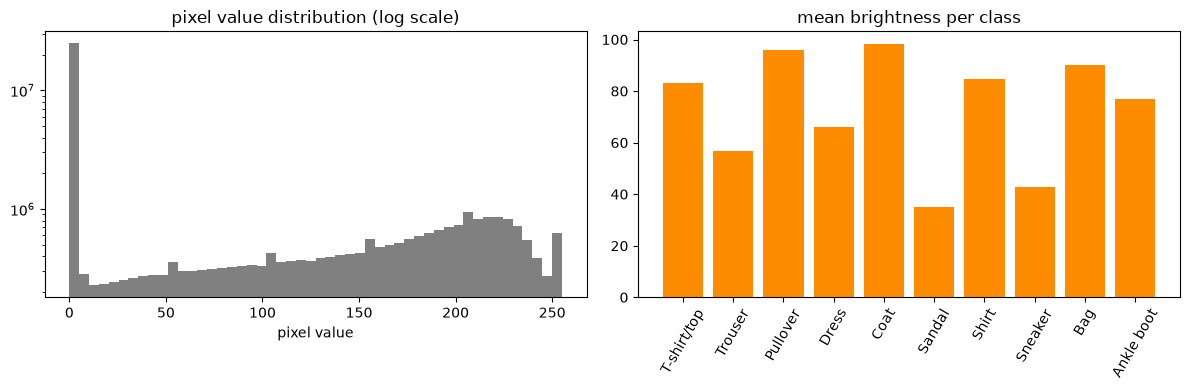

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# 전체 픽셀 히스토그램 (0에 몰려 있어서 로그 스케일)
axes[0].hist(X_train.flatten().numpy(), bins=50, color="gray")
axes[0].set_yscale("log")
axes[0].set_title("pixel value distribution (log scale)")
axes[0].set_xlabel("pixel value")

# 클래스별 평균 밝기
class_brightness = [X_train[y_train == c].float().mean().item() for c in range(10)]
axes[1].bar(class_names, class_brightness, color="darkorange")
axes[1].set_title("mean brightness per class")
axes[1].tick_params(axis="x", rotation=60)

plt.tight_layout()
plt.show()

## 정리

- train 60,000장, test 10,000장이고 이미지는 28×28 흑백이다.
- 픽셀 값은 0~255 정수라서, 모델에 넣기 전에 정규화가 필요하다.
- 클래스별 장수가 같아서(train 6,000 / test 1,000) 불균형 문제는 없다.
- 배경이 대부분 검은색(0)이라 픽셀 분포가 0 근처에 몰려 있다.
- 클래스마다 모양과 밝기 차이가 뚜렷해서 label을 조건으로 주고 생성하기에 좋은 데이터다.